<img alt="Logo da Universidade Federal do Ceará" src="../assets/logo-ufc.svg">

# **Pré-processamento dos Dados**

### **Objetivo do Notebook**

Este notebook tem o objetivo de preparar as bases que alimentam o site. Ele parte dos arquivos brutos (IPLANFOR, CNES, Censo 2022 por setor, malhas do IBGE e rede viária do OpenStreetMap) e termina com arquivos pré-processados, filtrados e prontos para serem consumidos na aplicação. A análise exploratória desses arquivos, com estatísticas descritivas, é realizada no notebook [`exploratory_analysis.ipynb`](./exploratory_analysis.ipynb).

**Fluxo de Trabalho**

| Etapa | O que acontece |
|---|---|
| 0. Configuração | Caminhos, nomes de colunas e parâmetros |
| 1. Censo 2022 | População e renda do responsável por setor |
| 2. Malhas | Setores e bairros de Fortaleza |
| 3. Setores | Junção, centroides e renda em salários mínimos |
| 4. CNES | Classificação, filtros e limpeza das unidades de saúde |
| 5. Distâncias e carga | Unidade mais próxima de cada setor, por nível, em linha reta e pela malha viária |
| 6. Desassistência | Classificação dos setores, com limiar mais rígido em zonas de vulnerabilidade econômica |
| 7. Exportação | CSV e GeoJSON finalizados + metadados |

### **Fontes de Dados**

**Malhas territoriais**

* Setores censitários de Fortaleza (2022) — [IBGE](https://mapas.fortaleza.ce.gov.br/mapa/786/setores-censitarios-2022), 2024.
* Bairros de Fortaleza — [IPLANFOR](https://mapas.fortaleza.ce.gov.br/mapa/21/bairros-de-fortaleza), 2023.
* Secretarias executivas regionais de Fortaleza — [IPLANFOR](https://mapas.fortaleza.ce.gov.br/mapa/17/secretarias-executivas-regionais), 2023.

**Censo 2022**

* Agregados por setores censitários — [IBGE](https://www.ibge.gov.br/), 2022. Foram utilizados a população residente e o rendimento nominal médio mensal dos responsáveis.

**Unidades de saúde**

* Cadastro Nacional de Estabelecimentos de Saúde (CNES) — [DATASUS](https://datasus.saude.gov.br/), com o respectivo dicionário de dados, 2026.

**Rede viária**

* OpenStreetMap — © colaboradores do [OpenStreetMap](https://www.openstreetmap.org/copyright), disponível sob a licença ODbL, obtida por meio da biblioteca `osmnx`.

## **0. Configuração**

Seção destinada a configuração de ambiente, caminhos, constantes, nomes de colunas e parâmetros do notebook.

### **Ambiente**

In [281]:
import json
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
pd.set_option("display.max_columns", 30)

### **Diretórios e Parâmetros Gerais**

In [282]:
# —————————— Pastas ——————————
DIR_BRUTOS = Path("../data/raw")    # Arquivos brutos baixados
DIR_SAIDA = Path("../data/output")  # Arquivos prontos para a aplicação
DIR_SAIDA.mkdir(parents=True, exist_ok=True)

# —————————— Arquivos de entrada ——————————
ARQ_SETORES_MALHA = DIR_BRUTOS / "ibge" / "FORTALEZA_malha_setores_censitarios.geojson"
ARQ_BAIRROS_MALHA = DIR_BRUTOS / "iplanfor" / "FORTALEZA_malha_bairros.geojson"
ARQ_CENSO_BASICO = DIR_BRUTOS / "ibge" / "BR_censo_2022_basico.csv"
ARQ_CENSO_RENDA = DIR_BRUTOS / "ibge" / "BR_censo_2022_renda.csv"
ARQ_CNES = DIR_BRUTOS / "cnes" / "BR_estabelecimentos_de_saude.csv"
ARQ_REGIONAIS = DIR_BRUTOS / "iplanfor" / "FORTALEZA_malha_regionais.geojson"

# —————————— Parâmetros gerais ——————————
COD_MUN = "2304400"     # Código de Fortaleza (IBGE)
CRS_GEO = "EPSG:4326"   # CRS em graus decimais: WGS 84, para coordenadas geográficas
CRS_UTM = "EPSG:31984"  # CRS em metros: SIRGAS 2000 / UTM 24S, para medir distâncias
BUFFER_M = 5_000        # Entorno de Fortaleza mantido para não criar vazios na borda

### **Censo**

In [283]:
# —————————— Configurações do Censo ——————————
SEP_CENSO, ENC_CENSO = ";", "latin-1"   # Separador e encoding dos arquivos do Censo 2022
COL_POP = "V0001"                       # População residente no setor
COL_RENDA = "V06004"                    # Rendimento nominal médio mensal dos responsáveis por domicílio (R$)

# Renda em salários mínimos (SM).
# Usa-se o salário mínimo vigente na data de referência do Censo 2022 (R$ 1.212).
SM_REF = 1212
CORTES_SM = [2, 5]                       # Limites das faixas, em SM
LABELS_SM = ["Até 2 SM", "De 2 a 5 SM", "Mais de 5 SM"]
FAIXA_BAIXA = LABELS_SM[0]               # Faixa de menor renda, usada na visualização

### **CNES**

In [284]:
# —————————— Configurações do CNES ——————————
# Nomes conferidos no dicionário de dados do CNES (tabela de estabelecimentos).
CNES_SEP = ";"
CNES_COLS = {
    "id": "CO_CNES",
    "nome": "NO_FANTASIA",
    "tipo": "TP_UNIDADE",
    "lat": "NU_LATITUDE",
    "lon": "NU_LONGITUDE",
    "contrato": "ST_CONTRATO_FORMALIZADO",
    "nat_jur": "CO_NATUREZA_JUR", 
    "motivo_desab": "CO_MOTIVO_DESAB",
}
VALORES_VERDADEIROS = {"1", "S", "SIM", "TRUE", "T", "Y"}

# Tipos do CNES que entram no estudo e o nível de cada um, baseado no documento de domínio do CNES
NIVEL_POR_TIPO = {
    1: 'UBS', 2: 'UBS', 15: 'UBS',       # Posto de saúde, centro de saúde/UBS, unidade mista
    73: 'UPA', 20: 'UPA', 21: 'UPA',     # Pronto atendimento
    5: 'Hospital', 7: 'Hospital',        # Hospital geral e hospital especializado
}
NIVEIS = {"UBS": "ubs", "UPA": "upa", "Hospital": "hosp"}   # Nome do nível -> Sufixo das colunas

# IDS de unidades do CNES a excluir do estudo (após conferência manual)
IDS_EXCLUIR = [
    # Oftalmologia
    "9112014", "3232891", "3051803", "2480638", "2561484",
    "2562480", "5121957", "6759122", "2480565",
    # Planos de saúde / uso restrito
    "3242587", "3528618", "2479907", "2611686", "6558895"
]

# Estrutura: {Nível: (limiar_moderado, limiar_severo)}, em metros
# Acima do moderado, o setor tem desassistência moderada; acima do severo, desassistência severa
LIMIARES = {
    "UBS": (1000, 1300), 
    "UPA": (3500, 4500),
    "Hospital": (3000, 4000)
}

### **Rede Viária (OSM)**

In [285]:
# —————————— Configurações da rede viária ——————————
DIR_OSM = DIR_BRUTOS / "osm"  # Redes baixadas do OpenStreetMap

# Modo de deslocamento de cada nível: a pé para a UBS e motorizado para UPA e hospital
REDE_POR_NIVEL = {"UBS": "walk", "UPA": "drive", "Hospital": "drive"}

### **Limiar Rígido em Zonas de Vulnerabilidade Econômica**

In [286]:
# —————————— Limiar rígido em zonas de vulnerabilidade econômica ——————————
LIMITE_VULNERAVEL_SM = 1  # Setor com renda média até este valor (em SM) é considerado vulnerável
FATOR_VULNERAVEL = 0.8    # Nos setores vulneráveis, os limiares são multiplicados por este fator

### **Funções auxiliares**

Define funções reaproveitadas ao longo do notebook. Com elas, é possível:
* União de geometrias;
* Leitura de colunas "verdadeiro/falso";
* Quantil ponderado por população (usado nas verificações);
* Limpeza de texto (remoção de acentos, espaços e caracteres especiais).

In [287]:
def uniao(geoms):
    """Faz a união de geometrias, seja uma lista ou um GeoSeries. Retorna uma única geometria."""
    return geoms.union_all() if hasattr(geoms, "union_all") else geoms.unary_union


def eh_verdadeiro(serie):
    """Verifica se os valores de uma série são "verdadeiros" (1, S, SIM, TRUE, T ou Y). Retorna uma série booleana"""
    return serie.astype(str).str.strip().str.upper().isin(VALORES_VERDADEIROS)


def quantil_ponderado(valores, pesos, qs):
    """Calcula quantis ponderados de uma lista de valores, com pesos. Retorna uma lista de quantis na mesma ordem de qs."""
    # Menor valor cuja população acumulada alcança cada quantil em qs
    d = pd.DataFrame({"v": valores, "p": pesos}).dropna().sort_values("v")
    v = d["v"].to_numpy()
    acum = (d["p"].cumsum() / d["p"].sum()).to_numpy()
    return [float(v[min(np.searchsorted(acum, q), len(v) - 1)]) for q in qs]


def limpar_texto(serie):
    """Padroniza uma coluna de texto: sem nulos e sem espaços nas pontas."""
    return serie.fillna("").astype(str).str.strip()

## **1. Censo 2022: população e renda por setor**

Os arquivos de agregados do Censo 2022 vêm para o Brasil inteiro e em texto, com vírgula decimal e marcas nas células suprimidas por sigilo. A função abaixo lê como texto, filtra Fortaleza pelo prefixo do `CD_SETOR` e converte os números. Já os valores suprimidos viram `NaN`.

O código do setor é mantido como **texto**, sem zeros à esquerda, porque no Censo 2022 ele pode conter letras.

In [288]:
def ler_agregados(caminho, colunas):
    df = pd.read_csv(caminho, sep=SEP_CENSO, encoding=ENC_CENSO, dtype=str)
    df.columns = df.columns.str.strip().str.upper()
    df["CD_SETOR"] = df["CD_SETOR"].str.strip()
    df = df[df["CD_SETOR"].str.startswith(COD_MUN)]
    df = df[["CD_SETOR", *colunas]].copy()
    for c in colunas:
        df[c] = pd.to_numeric(df[c].str.replace(",", ".", regex=False), errors="coerce")
    return df


# —————————— Leitura e padronização ——————————
pop = ler_agregados(ARQ_CENSO_BASICO, [COL_POP]).rename(columns={COL_POP: "populacao"})
renda = ler_agregados(ARQ_CENSO_RENDA, [COL_RENDA]).rename(columns={COL_RENDA: "renda"})
censo = pop.merge(renda, on="CD_SETOR", how="outer", validate="one_to_one")

# —————————— Conferência ——————————
print(f"Setores no Censo: {len(censo):,}")
print(f"População total: {censo['populacao'].sum():,.0f}")
print(f"Setores com renda suprimida ou ausente: {censo['renda'].isna().sum():,} "
      f"({censo['renda'].isna().mean():.1%})")
censo.head()

Setores no Censo: 4,408
População total: 2,428,708
Setores com renda suprimida ou ausente: 128 (2.9%)


,CD_SETOR,populacao,renda
0,230440005130001,866,"1,474.1"
1,230440005130002,35,"1,664.5"
2,230440005130003,125,"3,315.3"
3,230440005130004,266,"2,979.6"
4,230440005130005,4,NaN


## **2. Malhas de setores e de bairros**

Nesta etapa, são carregadas as malhas geográficas de setores censitários, bairros e regionais administrativas, mantendo-se apenas as colunas necessárias e padronizando-se os textos e os nomes das colunas.

O resultado são quatro dataframes: `setores`, com o código do setor e o nome do bairro; `bairros`, com o código, o nome e a regional de cada bairro; `regionais`, com a malha original das regionais; e `regionais_bairros`, que guarda cada pedaço de bairro dentro de uma regional, com sua área.

### **Leitura e Limpeza das Malhas**

In [289]:
# —————————— Setores censitários ——————————
setores = gpd.read_file(ARQ_SETORES_MALHA)
setores["CD_SETO"] = limpar_texto(setores["CD_SETO"]).str.replace("P", "", regex=False)
setores["Bairro"] = limpar_texto(setores["Bairro"])

setores = (
    setores[["CD_SETO", "Bairro", "geometry"]]
    .rename(columns={"CD_SETO": "CD_SETOR", "Bairro": "nome_bairro"})
    .copy()
)

# —————————— Bairros ——————————
bairros = gpd.read_file(ARQ_BAIRROS_MALHA)
bairros["Código do  IBGE"] = limpar_texto(bairros["Código do  IBGE"].astype("Int64"))
bairros["Nome"] = limpar_texto(bairros["Nome"])

bairros = (
    bairros[["Código do  IBGE", "Nome", "geometry"]]
    .rename(columns={"Código do  IBGE": "CD_BAIRRO", "Nome": "nome_bairro"})
    .copy()
)

# —————————— Regionais ——————————
regionais = gpd.read_file(ARQ_REGIONAIS)
regionais["regiao_adm"] = limpar_texto(regionais["regiao_adm"])

regionais = (
    regionais[["regiao_adm", "geometry"]]
    .rename(columns={"regiao_adm": "nome_regional"})
    .copy()
)

### **Cruzamento Espacial: Bairros x Regionais**

In [290]:
# Projeta para UTM (metros) para calcular interseção e área corretamente
bairros_utm = bairros.to_crs(CRS_UTM)
regionais_utm = regionais.to_crs(CRS_UTM)

# Uma única interseção serve para as duas saídas abaixo
inter = gpd.overlay(
    bairros_utm[["CD_BAIRRO", "nome_bairro", "geometry"]],
    regionais_utm[["nome_regional", "geometry"]],
    how="intersection",
    keep_geom_type=True,
)
inter["area_m2"] = inter.geometry.area

### **Dataframes Finais**

In [291]:
# —————————— Bairros com sua regional ——————————
# Bairro que cruza a divisa de duas regionais fica com a de maior área
regional_principal = (
    inter.sort_values("area_m2")
    .drop_duplicates("CD_BAIRRO", keep="last")
    [["CD_BAIRRO", "nome_regional"]]
)

bairros = bairros.merge(regional_principal, on="CD_BAIRRO", how="left")

# —————————— Regionais × bairros ——————————
regionais_bairros = (
    inter[["nome_regional", "CD_BAIRRO", "nome_bairro", "area_m2", "geometry"]]
    .to_crs(CRS_GEO)  # Retorna para lon/lat, como as demais bases
    .reset_index(drop=True)
)

### **Conferência de Dataframes Finais**

In [292]:
print(f"Setores: {len(setores):,} | Bairros: {len(bairros):,} | "
      f"Regionais: {len(regionais):,} | Regionais × Bairros: {len(regionais_bairros):,}")
print(f"CRS das malhas: {setores.crs}")
print(f"Bairros sem regional: {bairros['nome_regional'].isna().sum()}")

Setores: 4,422 | Bairros: 121 | Regionais: 12 | Regionais × Bairros: 121
CRS das malhas: EPSG:4326
Bairros sem regional: 0


## **3. Setores: junção e renda em salários mínimos**

Aqui os dados do Censo são unidos à malha pelo `CD_SETOR`. Em seguida:

- **Setores sem população** são eliminados, pois não pesam em nenhuma distância ou carga.
- **Centroides** são calculados em UTM 24S (metros) e também em lon/lat. O D3 usa lon/lat para desenhar e metros para a simulação da nova unidade.
- **Bairro e regional** são associados pelo nome do bairro. Os setores cujo nome não consta na malha de bairros (por grafia diferente, como "Dias Macêdo" e "Dias Macedo", ou por bairro inexistente nessa malha) são associados ao bairro que contém o seu ponto interno.
- **Renda em salários mínimos.** A base de agregados de 2022 traz a renda média dos responsáveis por setor (`V06004`), e não a contagem de pessoas por faixa salarial. Por isso, o corte é feito sobre essa média, convertida em SM. Os limites ficam em `CORTES_SM`.

> **Nota metodológica¹**: a renda é a média do setor, válida para todos os moradores dele. Um setor com média de 2 SM pode ter responsáveis muito abaixo e muito acima disso, e essa dispersão não aparece no corte.

> **Nota metodológica²**: o corte é por setor, não por pessoa. A população entra como peso nas somas, então a análise mede "quantas pessoas moram em setores de cada faixa", e não "quantas pessoas ganham cada faixa".

> **Nota metodológica³**: setores sem renda ficam como "Sem dado", para não sumirem da análise.

> **Nota metodológica⁴**: 45 setores do Censo (16.358 habitantes, cerca de 0,7% da população do município) não têm feição correspondente na malha de setores e, por isso, ficam fora da análise. Em sentido contrário, 59 feições da malha não têm registro no Censo e também são descartadas.


In [293]:
# —————————— Junção Censo + malha ——————————
fora_da_malha = censo[~censo["CD_SETOR"].isin(setores["CD_SETOR"])]
print(f"Setores do Censo sem feição na malha: {len(fora_da_malha):,} "
      f"({fora_da_malha['populacao'].sum():,.0f} habitantes)")

setores = setores.merge(censo, on="CD_SETOR", how="left", validate="one_to_one")

sem_censo = setores["populacao"].isna().sum()
print(f"Setores da malha sem correspondência no Censo: {sem_censo:,}")
assert sem_censo / len(setores) < 0.02, "Muitos setores sem par: confira o formato do CD_SETOR nos dois arquivos."

# —————————— Bairro (código e regional) ——————————
setores = setores.merge(bairros.drop(columns="geometry"), on="nome_bairro", how="left")

# Nomes grafados de forma diferente nas duas malhas não casam pelo nome.
# Esses setores recebem o bairro que contém o seu ponto interno.
sem_bairro = setores["CD_BAIRRO"].isna()
print(f"Setores com nome de bairro ausente na malha de bairros: {sem_bairro.sum():,} "
      f"({', '.join(sorted(setores.loc[sem_bairro, 'nome_bairro'].unique()))})")

cols_bairro = ["CD_BAIRRO", "nome_bairro", "nome_regional"]
pontos = setores.loc[sem_bairro, ["geometry"]].copy()
pontos["geometry"] = pontos.geometry.representative_point()
achados = gpd.sjoin(pontos, bairros[[*cols_bairro, "geometry"]], how="left", predicate="within")
achados = achados[~achados.index.duplicated()]
setores.loc[sem_bairro, cols_bairro] = achados[cols_bairro]

print(f"Setores sem bairro identificado: {setores['CD_BAIRRO'].isna().sum():,}")

# —————————— Remove setores sem população ——————————
vazios = (setores["populacao"].fillna(0) <= 0).sum()
setores = setores[setores["populacao"].fillna(0) > 0].copy()
print(f"Setores sem população removidos: {vazios:,} | Restantes: {len(setores):,}")
print(f"População total analisada: {setores['populacao'].sum():,.0f}")

# —————————— Projeção e centroides ——————————
setores = setores.to_crs(CRS_UTM)
cent = setores.geometry.centroid
cent_geo = cent.to_crs(CRS_GEO)
setores["x"], setores["y"] = cent.x.round(1), cent.y.round(1)
setores["lon"], setores["lat"] = cent_geo.x.round(6), cent_geo.y.round(6)

Setores do Censo sem feição na malha: 45 (16,358 habitantes)
Setores da malha sem correspondência no Censo: 59
Setores com nome de bairro ausente na malha de bairros: 134 (Boa Vista/Castelão, Dendê, Dias Macêdo, Sapiranga/Coité)
Setores sem bairro identificado: 0
Setores sem população removidos: 154 | Restantes: 4,268
População total analisada: 2,412,350


### **Renda Média em Salários Mínimos**

In [294]:
# —————————— Renda média em SM e faixas ——————————
setores["renda_sm"] = setores["renda"] / SM_REF

setores["faixa_renda"] = pd.cut(
    setores["renda_sm"],
    bins=[-np.inf, *CORTES_SM, np.inf],
    labels=LABELS_SM,
).astype(object).fillna("Sem dado")

print(f"Renda de referência: R$ {SM_REF:,} por salário mínimo")
print(f"Setores sem renda: {setores['renda'].isna().sum():,}")

resumo = setores.groupby("faixa_renda").agg(
    setores=("CD_SETOR", "count"), pessoas=("populacao", "sum"))
resumo["% da população"] = 100 * resumo["pessoas"] / resumo["pessoas"].sum()
resumo

Renda de referência: R$ 1,212 por salário mínimo
Setores sem renda: 25


,setores,pessoas,% da população
faixa_renda,,,
Até 2 SM,2920,"1,592,122.0",66.0
De 2 a 5 SM,893,"545,522.0",22.6
Mais de 5 SM,430,"274,523.0",11.4
Sem dado,25,183.0,0.0


## **4. CNES: unidades de saúde**

O arquivo do CNES é nacional e deve ser, portanto, filtrado conforme as regras de classificação, que seguem o dicionário de domínios do SCNES.

### **Classificação das Unidades**

Nesta etapa, adotou-se um mapeamento abrangente de estabelecimentos, a fim de refletir com maior fidelidade o funcionamento da rede do SUS em Fortaleza e a forma como a população efetivamente procura os serviços:

* **Atenção básica (UBS):** tipos 01 (posto de saúde), 02 (centro de saúde/UBS) e 15 (unidade mista). O código 15 representa estruturas que frequentemente absorvem a demanda de cuidados primários nos bairros.
* **Urgência e emergência (UPA):** tipos 73 (pronto atendimento), 20 (pronto-socorro geral) e 21 (pronto-socorro especializado). No domínio do SCNES, os códigos 20 e 21 são classificados como pronto-socorro, e não como UPA. A equivalência é uma escolha metodológica, justificada pelo fato de que, na rede municipal, os prontos-socorros funcionam como portas de entrada imediatas, com papel equivalente ao das UPAs no acesso do cidadão.
* **Atenção hospitalar:** tipos 05 (hospital geral) e 07 (hospital especializado). O código 07 representa grande parte da capacidade de internação da cidade e polos de referência de portas abertas ou reguladas, como maternidades públicas, hospitais infantis e de trauma (por exemplo, o IJF).

Essas decisões garantem que o cálculo de cobertura (distância e carga) dialogue com a infraestrutura de fato disponível à população de menor renda.

### **Limpeza**

A limpeza segue em ordem, registrando quantas unidades sobram a cada passo:

1. **Tipo** (`TP_UNIDADE`): apenas os tipos listados acima, que definem também o nível de cada unidade.
2. **Ativas**: estabelecimentos sem motivo de desativação (`CO_MOTIVO_DESAB` vazio). Unidades desativadas, mesmo que temporariamente, ficam de fora.
3. **Com atendimento SUS**: o contrato formalizado com o SUS (`ST_CONTRATO_FORMALIZADO` = S) identifica os prestadores privados e filantrópicos. As unidades públicas, que atendem pelo SUS sem contrato, são identificadas pela natureza jurídica (`CO_NATUREZA_JUR` iniciada em 1, administração pública). Postos de saúde (tipo 01) públicos só entram se tiverem contrato formalizado, pois nessa categoria há unidades que não são do SUS, como centros socioeducativos. Casos pontuais que não sejam SUS são retirados por conferência manual (`IDS_EXCLUIR`): Alguns exemplos são clínicas de oftalmologia e unidades de planos de saúde ou de uso restrito.
4. **Coordenadas válidas** (sem ausentes ou zeradas) e sem repetição do código CNES.
5. **Dentro de Fortaleza ou de um entorno de 5 km do limite municipal.** O raio corresponde ao maior limiar de análise (4500 m, UPA severo) somado a uma margem de segurança de 500 m. Unidades além desse raio não alteram a classificação de nenhum setor do município, nem em linha reta nem pela malha viária, já que o percurso pela via nunca é menor que a distância em linha reta. As que ficam logo além da divisa são mantidas para que setores de borda não sejam considerados sem atendimento apenas por causa do recorte territorial. Ao final da seção 5, as unidades do entorno que não são a mais próxima de nenhum setor de Fortaleza são removidas.


In [295]:
cols_usadas = [c for c in CNES_COLS.values() if c]
cnes = pd.read_csv(ARQ_CNES, sep=CNES_SEP, usecols=cols_usadas, dtype=str)
cnes = cnes.rename(columns={v: k for k, v in CNES_COLS.items() if v})

log = [("CNES (todas as linhas)", len(cnes))]

# 1) Tipos de interesse e nível
cnes["tipo"] = pd.to_numeric(cnes["tipo"], errors="coerce")
cnes = cnes[cnes["tipo"].isin(NIVEL_POR_TIPO)].copy()
cnes["nivel"] = cnes["tipo"].map(NIVEL_POR_TIPO)
log.append(("Tipos de interesse (UBS, UPA, hospital)", len(cnes)))

# 2) Ativas: sem motivo de desativação
cnes = cnes[cnes["motivo_desab"].fillna("").str.strip().eq("")].copy()
log.append(("Ativas (sem motivo de desativação)", len(cnes)))

# 3) Atende pelo SUS: contrato formalizado (privados/filantrópicos)
#    ou unidade pública (UBS, UPA, hospitais; exclui tipo 1 = posto de saúde)
contrato = eh_verdadeiro(cnes["contrato"].fillna(""))
publica = cnes["nat_jur"].fillna("").str.strip().str.startswith("1")
cnes = cnes[contrato | (publica & (cnes["tipo"] != 1))].copy()
log.append(("Atendem pelo SUS (contrato ou pública)", len(cnes)))

# 4) Coordenadas e duplicatas
for c in ["lat", "lon"]:
    cnes[c] = pd.to_numeric(cnes[c].str.replace(",", ".", regex=False), errors="coerce")
cnes = cnes.dropna(subset=["lat", "lon"])
cnes = cnes[(cnes["lat"] != 0) & (cnes["lon"] != 0)]
log.append(("Com coordenadas válidas", len(cnes)))

cnes = cnes.drop_duplicates("id")
cnes = cnes[~cnes["id"].isin(IDS_EXCLUIR)]
log.append(("Sem CNES repetido ou excluído", len(cnes)))

In [296]:
# 5) Recorte espacial: Fortaleza + entorno de 5 km
unidades = gpd.GeoDataFrame(
    cnes, geometry=gpd.points_from_xy(cnes["lon"], cnes["lat"]), crs=CRS_GEO
).to_crs(CRS_UTM)

contorno = uniao(bairros.to_crs(CRS_UTM).geometry)   # Limite de Fortaleza
area_busca = contorno.buffer(BUFFER_M)

unidades = unidades[unidades.within(area_busca)].copy()
log.append(("Dentro de Fortaleza + 5 km", len(unidades)))

# Mesmo nível e mesma coordenada = registro duplicado do mesmo equipamento
unidades["x"], unidades["y"] = unidades.geometry.x.round(1), unidades.geometry.y.round(1)
unidades = unidades.drop_duplicates(["nivel", "x", "y"]).reset_index(drop=True)
log.append(("Sem coordenadas repetidas por nível", len(unidades)))

unidades["em_fortaleza"] = unidades.within(contorno)

pd.DataFrame(log, columns=["etapa", "unidades"])

,etapa,unidades
0,CNES (todas as linhas),640122
1,"Tipos de interesse (UBS, UPA, hospital)",70256
2,Ativas (sem motivo de desativação),59956
3,Atendem pelo SUS (contrato ou pública),51648
4,Com coordenadas válidas,51648
5,Sem CNES repetido ou excluído,51635
6,Dentro de Fortaleza + 5 km,250
7,Sem coordenadas repetidas por nível,250


In [297]:
print(pd.crosstab(unidades["nivel"], unidades["em_fortaleza"].map({True: "Fortaleza", False: "Entorno 5 km"})))

# Lista de hospitais para conferência manual
(unidades[(unidades["nivel"] == "Hospital") & unidades["em_fortaleza"]]
    [["id", "nome", "tipo", "lat", "lon"]]
    .sort_values("nome")
    .to_csv(DIR_SAIDA / "conferir_hospitais.csv", index=False))

em_fortaleza  Entorno 5 km  Fortaleza
nivel                                
Hospital                 4         35
UBS                     60        137
UPA                      2         12


### **Conferência visual**

Os setores são desenhados em cinza, com a intensidade proporcional à população. As unidades de saúde são desenhadas por nível (UBS, UPA e hospital), com a contagem de cada um na legenda.

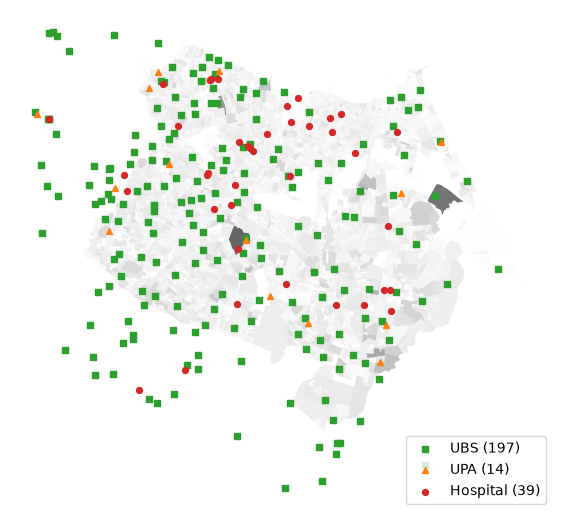

In [298]:
fig, ax = plt.subplots(figsize=(7, 7))
setores.plot(ax=ax, column="populacao", cmap="Greys", linewidth=0, alpha=0.6)
estilos = {"UBS": ("tab:green", "s"), "UPA": ("tab:orange", "^"), "Hospital": ("tab:red", "o")}
for nivel, (cor, marcador) in estilos.items():
    u = unidades[unidades["nivel"] == nivel]
    ax.scatter(u["x"], u["y"], c=cor, marker=marcador, s=18, label=f"{nivel} ({len(u)})")
ax.legend(loc="lower right")
ax.set_axis_off()
plt.show()

## **5. Distâncias e carga por unidade**

Para cada nível (UBS, UPA, hospital) é feito o cálculo de distância e carga, em três passos:

1. **Vizinho mais próximo:** Cada centroide de setor é ligado à unidade mais próxima em linha reta, por meio do algoritmo de árvore KD. Por fim, é armazenada a distância em metros e o código da unidade.
2. **Carga:** É somada a população dos setores atribuídos a cada unidade. As unidades que não são a mais próxima de ninguém ficam com carga 0; as do entorno nessa situação são removidas, pois não atendem a nenhum setor de Fortaleza, e as de Fortaleza são mantidas.
3. **Classe de carga:** Depois da remoção, as unidades de cada nível são divididas em quintis (1 = menor carga, 5 = maior), para a cor sequencial do mapa.

As unidades do entorno participam da busca, mas apenas a população de Fortaleza entra no cálculo da carga.

Esta seção utiliza a distância em linha reta. A distância pela malha viária é calculada ao final dela, apenas com as unidades que restam.


In [299]:
xy_setores = setores[["x", "y"]].to_numpy()
unidades["carga"] = np.nan
unidades["classe_carga"] = np.nan

for nivel, k in NIVEIS.items():
    un = unidades[unidades["nivel"] == nivel]

    # Vizinho mais próximo de cada setor
    arvore = cKDTree(un[["x", "y"]].to_numpy())
    dist, pos = arvore.query(xy_setores)
    setores[f"dist_{k}"] = dist.round(0).astype(int)
    setores[f"un_{k}"] = un["id"].to_numpy()[pos]

    # Carga por unidade
    carga = setores.groupby(f"un_{k}")["populacao"].sum()
    unidades.loc[un.index, "carga"] = un["id"].map(carga).fillna(0).round(0)

unidades["carga"] = unidades["carga"].astype(int)

# Unidade do entorno sem população atribuída não é a mais próxima de nenhum setor de Fortaleza e é removida
sem_uso = ~unidades["em_fortaleza"] & (unidades["carga"] == 0)
entorno_removidas = unidades.loc[sem_uso, "nivel"].value_counts().reindex(list(NIVEIS), fill_value=0)
print("Unidades do entorno removidas (carga 0):", entorno_removidas.to_dict())
unidades = unidades[~sem_uso].reset_index(drop=True)

# Quintis de carga dentro do nível (1 = menor carga, 5 = maior)
unidades["classe_carga"] = 0
for nivel in NIVEIS:
    ordem = unidades.loc[unidades["nivel"] == nivel, "carga"].rank(method="first")
    unidades.loc[ordem.index, "classe_carga"] = pd.qcut(ordem, min(5, len(ordem)), labels=False) + 1

unidades.groupby("nivel")["carga"].describe()[["count", "min", "50%", "max"]]

Unidades do entorno removidas (carga 0): {'UBS': 54, 'UPA': 1, 'Hospital': 2}


,count,min,50%,max
nivel,,,,
Hospital,37.0,"1,764.0","46,478.0","215,933.0"
UBS,143.0,431.0,"15,034.0","57,297.0"
UPA,13.0,"40,211.0","177,936.0","373,423.0"


### **Distância pela Malha Viária (OSM)**

Além da linha reta, a distância até a unidade mais próxima é calculada sobre a rede viária do OpenStreetMap (OSM), o que se aproxima do percurso real. O procedimento tem três passos:

1. **Rede:** a rede é baixada com o `osmnx` [1] para Fortaleza e o entorno de 5 km, o mesmo recorte das unidades, e armazenada. Utiliza-se a rede de pedestres (`walk`) para a UBS, cujo limiar se refere ao acesso a pé, e a rede de veículos (`drive`) para UPA e hospital, atendidos por deslocamento motorizado.
2. **Ligação à rede:** o centroide de cada setor e cada unidade são ligados ao nó mais próximo da rede, e essa distância de ligação é somada ao percurso.
3. **Caminho mais curto:** o algoritmo de Dijkstra é executado a partir das unidades de cada nível, no sentido inverso das vias, de modo que as mãos de direção sejam respeitadas no trajeto do setor até a unidade. O resultado é, para cada nó, a distância até a unidade mais próxima e qual é ela.

As colunas resultantes, `dist_via_*` e `un_via_*`, equivalem às de linha reta. A unidade mais próxima é escolhida pela rede, antes de somar as distâncias de ligação, o que é uma aproximação aceitável por serem distâncias pequenas diante dos limiares. A carga das unidades continua sendo calculada em linha reta, pois é essa a base da simulação de nova unidade no site.


In [304]:
def baixar_rede(modo):
    """Rede viária do OSM (Fortaleza + entorno) em UTM. Lê do cache se já tiver sido baixada."""
    caminho = DIR_OSM / f"FORTALEZA_rede_viaria_{modo}.graphml"
    if caminho.exists():
        G = ox.load_graphml(caminho)
    else:
        area_geo = gpd.GeoSeries([area_busca], crs=CRS_UTM).to_crs(CRS_GEO).iloc[0]
        G = ox.project_graph(ox.graph_from_polygon(area_geo, network_type=modo), to_crs=CRS_UTM)
        DIR_OSM.mkdir(parents=True, exist_ok=True)
        ox.save_graphml(G, caminho)
    # Só a maior componente fortemente conectada: todo nó alcança todos os outros, respeitando as mãos de direção
    return ox.truncate.largest_component(G, strongly=True)


def distancia_pela_rede(G, xy_origens, xy_destinos):
    """Distância (m) pela rede de cada origem ao destino mais próximo, e a posição desse destino em xy_destinos."""
    nos = list(G.nodes)
    arvore = cKDTree(np.array([[G.nodes[n]["x"], G.nodes[n]["y"]] for n in nos]))

    # Cada ponto é ligado ao nó mais próximo da rede
    lig_origem, no_origem = arvore.query(xy_origens)
    lig_destino, no_destino = arvore.query(xy_destinos)

    # Dijkstra a partir dos destinos, na rede invertida (trajeto origem -> destino)
    pesos = nx.to_scipy_sparse_array(ox.convert.to_digraph(G, weight="length"), nodelist=nos, weight="length")
    dist_no, pred, fonte = dijkstra(pesos.T, directed=True, indices=np.unique(no_destino),
                                 min_only=True, return_predecessors=True)
    assert np.isfinite(dist_no[no_origem]).all(), "Há setores sem caminho até uma unidade: confira a rede baixada."

    # Se mais de um destino cair no mesmo nó, vale o que está mais perto da rede
    por_no = (pd.DataFrame({"no": no_destino, "lig": lig_destino}).reset_index()
              .sort_values("lig").drop_duplicates("no").set_index("no")["index"])
    pos = por_no.loc[fonte[no_origem]].to_numpy()
    rota = {"nos": nos, "pred": pred, "no_origem": no_origem, "no_destino": no_destino}
    return dist_no[no_origem] + lig_origem + lig_destino[pos], pos, lig_origem, rota


redes = {}
rotas_info = {}   # Predecessores do Dijkstra por nível, usados para desenhar as vias de ligação no GeoPackage
for nivel, k in NIVEIS.items():
    modo = REDE_POR_NIVEL[nivel]
    if modo not in redes:
        redes[modo] = baixar_rede(modo)
        print(f"Rede '{modo}': {redes[modo].number_of_nodes():,} nós | {redes[modo].number_of_edges():,} trechos")

    un = unidades[unidades["nivel"] == nivel]
    dist, pos, lig, rota = distancia_pela_rede(redes[modo], xy_setores, un[["x", "y"]].to_numpy())
    rotas_info[nivel] = {**rota, "pos": pos, "modo": modo}
    setores[f"dist_via_{k}"] = dist.round(0).astype(int)
    setores[f"un_via_{k}"] = un["id"].to_numpy()[pos]

    razao = setores[f"dist_via_{k}"] / setores[f"dist_{k}"].replace(0, np.nan)
    print(f"{nivel}: mediana via / linha reta = {razao.median():.2f} | "
          f"ligação setor-rede: mediana {np.median(lig):.0f} m, máxima {lig.max():.0f} m")

Rede 'walk': 100,249 nós | 297,886 trechos
UBS: mediana via / linha reta = 1.46 | ligação setor-rede: mediana 34 m, máxima 523 m
Rede 'drive': 50,475 nós | 132,982 trechos
UPA: mediana via / linha reta = 1.36 | ligação setor-rede: mediana 43 m, máxima 802 m
Hospital: mediana via / linha reta = 1.40 | ligação setor-rede: mediana 43 m, máxima 802 m


## **6. Classificação de desassistência**

Cada setor é classificado, em cada nível de saúde, a partir da distância até a unidade mais próxima:

| Classe | Significado | Distância |
|---|---|---|
| 0 | Adequado | Até o limiar moderado |
| 1 | Desassistência moderada | Entre o limiar moderado e o severo |
| 2 | Desassistência severa | Além do limiar severo |

A classificação é feita para a distância em linha reta (`cls_*`) e para a distância pela malha viária (`cls_via_*`), com os mesmos limiares, já que eles se referem a percursos.

### **Limiar Mais Rígido em Zonas de Vulnerabilidade Econômica**

A mesma distância não representa a mesma barreira para todos os moradores. Em setores de renda mais baixa, é maior a dependência do deslocamento a pé ou do transporte público, e menor o acesso a veículo próprio. Por isso, nos setores vulneráveis, os limiares moderado e severo são multiplicados por `FATOR_VULNERAVEL`, o que os torna mais curtos e, portanto, mais exigentes.

É considerado vulnerável o setor com renda média de até `LIMITE_VULNERAVEL_SM` salário mínimo (1 SM). O corte é mais baixo que o da faixa "Até 2 SM", que reúne cerca de dois terços da população e não discriminaria a vulnerabilidade. Setores sem dado de renda não são considerados vulneráveis, o que afeta uma parcela desprezível da população.

> **Nota metodológica**: o valor do fator é uma escolha de projeto e não decorre de uma referência normativa.


In [305]:
# —————————— Setores vulneráveis e fator de cada setor ——————————
setores["vulneravel"] = setores["renda_sm"] <= LIMITE_VULNERAVEL_SM   # Sem dado de renda resulta em False
fator = np.where(setores["vulneravel"], FATOR_VULNERAVEL, 1.0)


def classificar(dist, limiares, fator):
    """Classe de desassistência: 0 = adequado, 1 = moderada, 2 = severa. O limiar de cada setor é multiplicado por fator."""
    moderado, severo = limiares
    return (dist > moderado * fator).astype(int) + (dist > severo * fator).astype(int)


for nivel, k in NIVEIS.items():
    setores[f"cls_{k}"] = classificar(setores[f"dist_{k}"], LIMIARES[nivel], fator)
    setores[f"cls_via_{k}"] = classificar(setores[f"dist_via_{k}"], LIMIARES[nivel], fator)

pct_vulneravel = 100 * setores.loc[setores["vulneravel"], "populacao"].sum() / setores["populacao"].sum()
print(f"Setores vulneráveis: {setores['vulneravel'].sum():,} ({pct_vulneravel:.1f}% da população)")
print(f"Fator aplicado aos limiares dos vulneráveis: {FATOR_VULNERAVEL}")
setores[[c for c in setores.columns if c.startswith("cls")]].apply(pd.Series.value_counts).fillna(0).astype(int)

Setores vulneráveis: 645 (12.4% da população)
Fator aplicado aos limiares dos vulneráveis: 0.8


,cls_ubs,cls_via_ubs,cls_upa,cls_via_upa,cls_hosp,cls_via_hosp
0,3642,2683,3077,2218,3732,3180
1,400,767,702,668,308,544
2,226,818,489,1382,228,544


## **7. Exportação dos arquivos para consumo D3**

| Arquivo | Conteúdo |
|---|---|
| `setores.geojson` | Só a geometria e as chaves `CD_SETOR` e `CD_BAIRRO` |
| `setores.csv` | Atributos por setor: população, renda média (R$ e SM), faixa de renda, centroide (lon/lat e metros), distância e unidade mais próxima por nível (em linha reta, `dist_*` e `un_*`, e pela malha viária, `dist_via_*` e `un_via_*`), indicador de vulnerabilidade econômica e classe de desassistência (`cls_*` e `cls_via_*`) |
| `unidades.csv` | Unidades com nome, nível, coordenadas, carga e classe de carga |
| `bairros.geojson` | Polígonos de bairro com nome, regional, população, renda média em SM e % da população na faixa de menor renda, além de indicadores por nível: mediana ponderada da distância, carga média das unidades que atendem o bairro e % da população em desassistência moderada e severa, em linha reta e pela via |
| `cobertura.csv` | Curva de cobertura acumulada: % da população a até *d* metros da unidade mais próxima, por base de distância, nível e faixa de renda |
| `metadados.json` | Salário de referência, cortes, faixas, proporção de renda suprimida, limiares, regra do limiar rígido, modo da rede viária, CRS e contagens |

A geometria é simplificada em 10 m (em UTM) e as coordenadas são arredondadas na 5ª casa decimal. Isso reduz bastante o tamanho sem alterar o desenho em escala de cidade. Como o D3 precisa de lon/lat, os GeoJSON saem em WGS 84, enquanto as colunas `x` e `y` dos CSVs ficam em metros para a simulação.

In [306]:
def salvar_geojson(gdf, nome, tolerancia_m=10):
    g = gdf.copy()
    n_antes = len(g)
    g["geometry"] = g.geometry.simplify(tolerancia_m)      # ainda em UTM, tolerância em metros
    g = g.to_crs(CRS_GEO)
    g["geometry"] = gpd.GeoSeries(
        shapely.set_precision(np.asarray(g.geometry), 1e-5), index=g.index, crs=CRS_GEO)
    caminho = DIR_SAIDA / nome
    caminho.unlink(missing_ok=True)
    g.to_file(caminho, driver="GeoJSON")
    print(f"✔ {nome}: {n_antes} feições | {len(g.columns) - 1} atributos | "
          f"tolerância {tolerancia_m} m | {caminho.stat().st_size / 1e6:.2f} MB")


print(f"Saída em: {DIR_SAIDA}\n")

# —————————— Setores: geometria + tabela de atributos ——————————
print("▶ Setores")
salvar_geojson(setores[["CD_SETOR", "CD_BAIRRO", "geometry"]], "setores.geojson")

colunas_setores = [
    "CD_SETOR", "CD_BAIRRO", "nome_bairro", "nome_regional", "populacao",
    "renda", "renda_sm", "faixa_renda", "x", "y", "lon", "lat",
]
colunas_setores += [f"{p}_{k}" for k in NIVEIS.values() for p in ("dist", "un")]
colunas_setores += [f"{p}_{k}" for k in NIVEIS.values() for p in ("dist_via", "un_via")]
colunas_setores += ["vulneravel"] + [f"{p}_{k}" for k in NIVEIS.values() for p in ("cls", "cls_via")]

setores_csv = pd.DataFrame(setores[colunas_setores]).copy()
setores_csv["renda"] = setores_csv["renda"].round(0)
setores_csv["renda_sm"] = setores_csv["renda_sm"].round(2)
setores_csv.to_csv(DIR_SAIDA / "setores.csv", index=False)
print(f"✔ setores.csv: {len(setores_csv)} linhas | {len(colunas_setores)} colunas | "
      f"{(DIR_SAIDA / 'setores.csv').stat().st_size / 1e6:.2f} MB")
print(f"  população total: {setores_csv['populacao'].sum():,.0f}")
print(f"  setores sem renda: {setores_csv['renda'].isna().sum()} "
      f"({100 * setores_csv['renda'].isna().mean():.1f}%)")
print("  distribuição por faixa:")
print(setores_csv["faixa_renda"].value_counts(dropna=False).to_string())

# —————————— Unidades ——————————
print("\n▶ Unidades")
unidades_csv = unidades[["id", "nome", "nivel", "em_fortaleza", "lon", "lat", "x", "y", "carga", "classe_carga"]]
unidades_csv.to_csv(DIR_SAIDA / "unidades.csv", index=False)
print(f"✔ unidades.csv: {len(unidades_csv)} linhas | "
      f"{(DIR_SAIDA / 'unidades.csv').stat().st_size / 1e6:.2f} MB")
print("  por nível (total | dentro de Fortaleza):")
print(unidades_csv.groupby("nivel")["em_fortaleza"].agg(total="size", dentro="sum").to_string())

# —————————— Bairros ——————————
print("\n▶ Bairros")
# Renda média do bairro: média dos setores ponderada pela população, só com setores que têm renda
bairros_utm = bairros.to_crs(CRS_UTM)
com_renda = setores[setores["renda"].notna()].copy()
com_renda["renda_x_pop"] = com_renda["renda"] * com_renda["populacao"]
agg_renda = com_renda.groupby("CD_BAIRRO").agg(soma=("renda_x_pop", "sum"), pop=("populacao", "sum"))

bairros_utm["populacao"] = bairros_utm["CD_BAIRRO"].map(
    setores.groupby("CD_BAIRRO")["populacao"].sum()).fillna(0).round(0).astype(int)
bairros_utm["renda_media_sm"] = (
    bairros_utm["CD_BAIRRO"].map(agg_renda["soma"] / agg_renda["pop"]) / SM_REF
).round(2)

# % da população do bairro que mora em setores da faixa de menor renda
pop_baixa = setores[setores["faixa_renda"] == FAIXA_BAIXA].groupby("CD_BAIRRO")["populacao"].sum()
pop_com_renda = setores[setores["renda"].notna()].groupby("CD_BAIRRO")["populacao"].sum()
bairros_utm["pct_pop_baixa_renda"] = (
    100 * bairros_utm["CD_BAIRRO"].map(pop_baixa / pop_com_renda)
).round(1)

# Indicadores por nível: distância, carga e desassistência (setores ponderados pela população do bairro)
carga_por_id = unidades.set_index("id")["carga"]


def indicadores_bairro(g):
    pop = g["populacao"]
    r = {}
    for k in NIVEIS.values():
        r[f"dist_{k}"] = quantil_ponderado(g[f"dist_{k}"], pop, [0.5])[0]
        r[f"dist_via_{k}"] = quantil_ponderado(g[f"dist_via_{k}"], pop, [0.5])[0]
        r[f"carga_{k}"] = np.average(g[f"un_{k}"].map(carga_por_id), weights=pop)
        for p in ("", "_via"):
            r[f"pct_mod{p}_{k}"] = 100 * pop[g[f"cls{p}_{k}"] >= 1].sum() / pop.sum()
            r[f"pct_sev{p}_{k}"] = 100 * pop[g[f"cls{p}_{k}"] == 2].sum() / pop.sum()
    return pd.Series(r)


ind = pd.DataFrame({cd: indicadores_bairro(g) for cd, g in setores.groupby("CD_BAIRRO")}).T
for c in ind.columns:
    bairros_utm[c] = bairros_utm["CD_BAIRRO"].map(ind[c]).round(0 if c.startswith(("dist", "carga")) else 1)

print(f"  bairros: {len(bairros_utm)} | "
      f"sem renda: {bairros_utm['renda_media_sm'].isna().sum()} | "
      f"sem população: {(bairros_utm['populacao'] == 0).sum()}")
print(f"  renda média (SM): min {bairros_utm['renda_media_sm'].min():.2f} | "
      f"mediana {bairros_utm['renda_media_sm'].median():.2f} | "
      f"max {bairros_utm['renda_media_sm'].max():.2f}")
print(f"  população total nos bairros: {bairros_utm['populacao'].sum():,.0f}")

salvar_geojson(bairros_utm, "bairros.geojson")

# —————————— Curva de cobertura ——————————
print("\n▶ Cobertura")
cols_dist = [c for c in setores.columns if c.startswith("dist")]
grade = np.arange(0, np.ceil(setores[cols_dist].to_numpy().max() / 100) * 100 + 100, 100)   # Passo de 100 m
linhas = []
for base, p in [("linha_reta", "dist"), ("via", "dist_via")]:
    for nivel, k in NIVEIS.items():
        for faixa, g in [("Todas", setores), *setores.groupby("faixa_renda")]:
            d, pop = g[f"{p}_{k}"].to_numpy(), g["populacao"].to_numpy()
            ordem = np.argsort(d)
            acum = np.cumsum(pop[ordem]) / pop.sum()
            n_ate = np.searchsorted(d[ordem], grade, side="right")   # Setores a até d metros
            pct = np.where(n_ate > 0, acum[np.maximum(n_ate - 1, 0)], 0)
            linhas += [(base, nivel, faixa, int(x), round(100 * v, 2)) for x, v in zip(grade, pct)]

cobertura = pd.DataFrame(linhas, columns=["base", "nivel", "faixa", "distancia_m", "pct_pop_ate"])
cobertura.to_csv(DIR_SAIDA / "cobertura.csv", index=False)
print(f"✔ cobertura.csv: {len(cobertura)} linhas | {(DIR_SAIDA / 'cobertura.csv').stat().st_size / 1e6:.2f} MB")

print("\nExportação concluída.")

Saída em: ../data/output

▶ Setores
✔ setores.geojson: 4268 feições | 2 atributos | tolerância 10 m | 1.52 MB
✔ setores.csv: 4268 linhas | 31 colunas | 0.89 MB
  população total: 2,412,350
  setores sem renda: 25 (0.6%)
  distribuição por faixa:
faixa_renda
Até 2 SM        2920
De 2 a 5 SM      893
Mais de 5 SM     430
Sem dado          25

▶ Unidades
✔ unidades.csv: 193 linhas | 0.02 MB
  por nível (total | dentro de Fortaleza):
          total  dentro
nivel                  
Hospital     37      35
UBS         143     137
UPA          13      12

▶ Bairros
  bairros: 121 | sem renda: 0 | sem população: 0
  renda média (SM): min 1.05 | mediana 1.80 | max 12.35
  população total nos bairros: 2,412,350
✔ bairros.geojson: 121 feições | 27 atributos | tolerância 10 m | 0.17 MB

▶ Cobertura
✔ cobertura.csv: 3510 linhas | 0.12 MB

Exportação concluída.


In [307]:
# —————————— Metadados ——————————
pop_total = setores["populacao"].sum()

sem_renda = setores["renda"].isna()

metadados = {
    "gerado_em": date.today().isoformat(),
    "municipio": COD_MUN,
    "crs_geometria": CRS_GEO,
    "crs_metros": CRS_UTM,
    "n_setores": int(len(setores)),
    "populacao_total": int(pop_total),
    "renda": {
        "fonte": "Censo 2022, agregados por setor: rendimento nominal médio mensal dos responsáveis",
        "salario_minimo_referencia_reais": SM_REF,
        "cortes_sm": CORTES_SM,
        "faixas": LABELS_SM,
        "limitacao": "renda média por setor",
        "pct_setores_sem_dado": round(100 * sem_renda.mean(), 2),
        "pct_populacao_sem_dado": round(100 * setores.loc[sem_renda, "populacao"].sum() / pop_total, 2),
    },
    "limiares_m": LIMIARES,
    "limiar_rigido": {
        "descricao": "Em setores com renda média até o limite, os limiares são multiplicados pelo fator",
        "renda_sm_ate": LIMITE_VULNERAVEL_SM,
        "fator": FATOR_VULNERAVEL,
        "pct_populacao_vulneravel": round(100 * setores.loc[setores["vulneravel"], "populacao"].sum() / pop_total, 2),
    },
    "unidades_entorno_removidas": {n: int(entorno_removidas[n]) for n in NIVEIS},
    "classes_desassistencia": {"0": "adequado", "1": "moderada", "2": "severa"},
    "rede_viaria": {"fonte": "OpenStreetMap, via osmnx", "modo_por_nivel": REDE_POR_NIVEL},
    "unidades": {n: int((unidades["nivel"] == n).sum()) for n in NIVEIS},
    "buffer_entorno_m": BUFFER_M,
}

with open(DIR_SAIDA / "metadados.json", "w", encoding="utf-8") as f:
    json.dump(metadados, f, ensure_ascii=False, indent=2)

print(json.dumps(metadados, ensure_ascii=False, indent=2))

{
  "gerado_em": "2026-11-07",
  "municipio": "2304400",
  "crs_geometria": "EPSG:4326",
  "crs_metros": "EPSG:31984",
  "n_setores": 4268,
  "populacao_total": 2412350,
  "renda": {
    "fonte": "Censo 2022, agregados por setor: rendimento nominal médio mensal dos responsáveis",
    "salario_minimo_referencia_reais": 1212,
    "cortes_sm": [
      2,
      5
    ],
    "faixas": [
      "Até 2 SM",
      "De 2 a 5 SM",
      "Mais de 5 SM"
    ],
    "limitacao": "renda média por setor",
    "pct_setores_sem_dado": 0.59,
    "pct_populacao_sem_dado": 0.01
  },
  "limiares_m": {
    "UBS": [
      1000,
      1300
    ],
    "UPA": [
      3500,
      4500
    ],
    "Hospital": [
      3000,
      4000
    ]
  },
  "limiar_rigido": {
    "descricao": "Em setores com renda média até o limite, os limiares são multiplicados pelo fator",
    "renda_sm_ate": 1,
    "fator": 0.8,
    "pct_populacao_vulneravel": 12.4
  },
  "unidades_entorno_removidas": {
    "UBS": 54,
    "UPA": 1,
    "Ho

### **Exportação para análise no QGIS**

Além dos arquivos enxutos para o site, que continuam sendo gerados como antes, esta etapa grava um único GeoPackage em `data/output/qgis/analise_fortaleza.gpkg`, com tudo já unido para análise em SIG. Ele não substitui os arquivos da seção anterior, apenas facilita a análise no QGIS.

| Camada | Geometria | Conteúdo |
|---|---|---|
| `setores` | Polígono | Todos os atributos de `setores.csv`, mais o nome e a carga da unidade mais próxima de cada nível, em linha reta e pela via |
| `bairros` | Polígono | Os indicadores de `bairros.geojson` |
| `unidades` | Ponto | Os atributos de `unidades.csv`, mais o tipo CNES |
| `centroides` | Ponto | Centroide de cada setor, com os atributos de identificação e população |
| `linhas_retas` | Linha | Segmento reto do centroide de cada setor até a unidade mais próxima em linha reta, de cada nível (uma linha por setor e nível), com a distância, a unidade e a classe de desassistência |
| `vias_ligacao` | Linha | Percurso pela malha viária de cada setor até a unidade mais próxima de cada nível (uma linha por setor e nível), com a distância, a unidade e a classe de desassistência |

As `linhas_retas` correspondem a `dist_*` e permitem comparar, no mapa, a unidade mais próxima em linha reta com a escolhida pela rede (`vias_ligacao`). As `vias_ligacao` seguem o mesmo cálculo de `dist_via_*`: o trecho reto do centroide até o nó mais próximo da rede, o caminho mais curto respeitando as mãos de direção (com a geometria real das vias do OSM) e o trecho reto do último nó até a unidade. Assim, o comprimento da linha equivale a `dist_via_*`, a menos de arredondamentos.

Diferenças em relação aos arquivos do site:

* **Geometria original**, sem simplificação nem arredondamento.
* **Um só CRS (SIRGAS 2000 / UTM 24S, em metros)** em todas as camadas, o que facilita medir distâncias e criar *buffers* no QGIS. As colunas `lon` e `lat` continuam disponíveis.
* **Nomes de coluna completos** e booleanos de verdade.

In [ ]:
# —————————— GeoPackage para QGIS ——————————
DIR_QGIS = DIR_SAIDA / "qgis"
DIR_QGIS.mkdir(parents=True, exist_ok=True)
ARQ_GPKG = DIR_QGIS / "analise_fortaleza.gpkg"
ARQ_GPKG.unlink(missing_ok=True)

nome_un = unidades.set_index("id")["nome"]
carga_un = unidades.set_index("id")["carga"]

# Setores: geometria original em UTM + atributos + dados da unidade mais próxima
setores_qgis = setores[colunas_setores + ["geometry"]].to_crs(CRS_UTM).copy()
setores_qgis["renda"] = setores_qgis["renda"].round(0)
setores_qgis["renda_sm"] = setores_qgis["renda_sm"].round(2)
for k in NIVEIS.values():
    for p in ("un", "un_via"):
        setores_qgis[f"nome_{p}_{k}"] = setores_qgis[f"{p}_{k}"].map(nome_un)
        setores_qgis[f"carga_{p}_{k}"] = setores_qgis[f"{p}_{k}"].map(carga_un)

# Unidades: pontos em UTM
unidades_qgis = unidades[["id", "nome", "nivel", "tipo", "em_fortaleza", "lon", "lat", "x", "y",
                          "carga", "classe_carga", "geometry"]].to_crs(CRS_UTM)

# Centroides dos setores: pontos em UTM
centroides_qgis = gpd.GeoDataFrame(
    setores[["CD_SETOR", "CD_BAIRRO", "nome_bairro", "populacao", "renda_sm", "x", "y", "lon", "lat"]].drop(columns="geometry", errors="ignore"),
    geometry=gpd.points_from_xy(setores["x"], setores["y"]), crs=CRS_UTM)


# Vias de ligação: percurso pela rede de cada setor até a unidade mais próxima, por nível
def geometria_trecho(G, u, v):
    """Coordenadas do trecho u -> v: geometria do OSM, se houver, ou reta entre os nós (escolhe o paralelo mais curto)."""
    dados = min(G[u][v].values(), key=lambda d: d.get("length", np.inf))
    if "geometry" in dados:
        coords = list(dados["geometry"].coords)
        pu = np.array([G.nodes[u]["x"], G.nodes[u]["y"]])
        if np.hypot(*(np.array(coords[0]) - pu)) > np.hypot(*(np.array(coords[-1]) - pu)):
            coords.reverse()          # Garante o sentido u -> v
        return coords
    return [(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])]


vias = []
for nivel, k in NIVEIS.items():
    info = rotas_info[nivel]
    G, nos, pred = redes[info["modo"]], info["nos"], info["pred"]
    un = unidades[unidades["nivel"] == nivel].reset_index(drop=True)
    cache_trechos = {}
    for i in range(len(setores)):
        no = info["no_origem"][i]
        coords = [tuple(xy_setores[i])]
        while True:                                   # Segue os predecessores até chegar ao nó da unidade
            coords.append((G.nodes[nos[no]]["x"], G.nodes[nos[no]]["y"]))
            prox = pred[no]
            if prox < 0:
                break
            if (no, prox) not in cache_trechos:
                cache_trechos[(no, prox)] = geometria_trecho(G, nos[no], nos[prox])
            coords.extend(cache_trechos[(no, prox)][1:])
            no = prox
        coords.append(tuple(un.loc[info["pos"][i], ["x", "y"]]))
        vias.append({"CD_SETOR": setores["CD_SETOR"].iloc[i], "nivel": nivel, "modo_rede": info["modo"],
                     "id_unidade": setores[f"un_via_{k}"].iloc[i], "dist_via_m": setores[f"dist_via_{k}"].iloc[i],
                     "cls_via": setores[f"cls_via_{k}"].iloc[i], "geometry": shapely.LineString(coords)})

vias_qgis = gpd.GeoDataFrame(vias, crs=CRS_UTM)
vias_qgis["nome_unidade"] = vias_qgis["id_unidade"].map(nome_un)
vias_qgis["comprimento_m"] = vias_qgis.length.round(0)

# Linhas retas: centroide do setor -> unidade mais próxima em linha reta, por nível
xy_un = unidades.set_index("id")[["x", "y"]]
retas = []
for nivel, k in NIVEIS.items():
    destino = xy_un.loc[setores[f"un_{k}"]].to_numpy()
    for i in range(len(setores)):
        retas.append({"CD_SETOR": setores["CD_SETOR"].iloc[i], "nivel": nivel,
                      "id_unidade": setores[f"un_{k}"].iloc[i], "dist_m": setores[f"dist_{k}"].iloc[i],
                      "cls": setores[f"cls_{k}"].iloc[i],
                      "geometry": shapely.LineString([tuple(xy_setores[i]), tuple(destino[i])])})
retas_qgis = gpd.GeoDataFrame(retas, crs=CRS_UTM)
retas_qgis["nome_unidade"] = retas_qgis["id_unidade"].map(nome_un)

camadas = {"setores": setores_qgis, "bairros": bairros_utm, "unidades": unidades_qgis,
           "centroides": centroides_qgis, "linhas_retas": retas_qgis, "vias_ligacao": vias_qgis}
for nome, gdf in camadas.items():
    gdf.to_file(ARQ_GPKG, layer=nome, driver="GPKG")
    print(f"✔ camada {nome}: {len(gdf)} feições | {len(gdf.columns) - 1} atributos")
print(f"\n{ARQ_GPKG.name}: {ARQ_GPKG.stat().st_size / 1e6:.2f} MB")

## **Referências**

[1] BOEING, G. OSMnx: new methods for acquiring, constructing, analyzing, and visualizing complex street networks. *Computers, Environment and Urban Systems*, v. 65, p. 126–139, 2017. DOI: 10.1016/j.compenvurbsys.2017.05.004.

[2] IBGE. *Censo Demográfico 2022*: agregados por setores censitários. Rio de Janeiro: IBGE, 2024. Diponível em: https://www.ibge.gov.br/estatisticas/sociais/populacao/22838-censo-demografico-2022.html?=&t=o-que-e.

[3] IBGE. *Setores censitários de Fortaleza (2022)*. Mapas Fortaleza, 2024. Disponível em: https://mapas.fortaleza.ce.gov.br/mapa/786/setores-censitarios-2022.

[4] IPLANFOR. *Bairros de Fortaleza*. Mapas Fortaleza, 2023. Disponível em: https://mapas.fortaleza.ce.gov.br/mapa/21/bairros-de-fortaleza.

[5] MINISTÉRIO DA SAÚDE. DATASUS. *Cadastro Nacional de Estabelecimentos de Saúde (CNES)*: dicionário de dados e arquivo de estabelecimentos. Brasília: Ministério da Saúde, 2026. Disponível em: https://datasus.saude.gov.br/cnes.

[6] OPENSTREETMAP CONTRIBUTORS. *OpenStreetMap*. Disponível em: https://www.openstreetmap.org. Dados disponíveis sob a licença ODbL.
